In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings("ignore")

In [49]:
df=pd.read_csv("smoking.csv") 
x_train = pd.read_csv("x_train.csv") 
x_test = pd.read_csv("x_test.csv") 
y_train = pd.read_csv("y_train.csv") 
y_test = pd.read_csv("y_test.csv")

In [50]:
df

,ID,gender,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),...,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,oral,dental caries,tartar,smoking
0,0,F,40,155,60,81.3,1.2,1.0,1.0,1.0,...,12.9,1.0,0.7,18.0,19.0,27.0,Y,0,Y,0
1,1,F,40,160,60,81.0,0.8,0.6,1.0,1.0,...,12.7,1.0,0.6,22.0,19.0,18.0,Y,0,Y,0
2,2,M,55,170,60,80.0,0.8,0.8,1.0,1.0,...,15.8,1.0,1.0,21.0,16.0,22.0,Y,0,N,1
3,3,M,40,165,70,88.0,1.5,1.5,1.0,1.0,...,14.7,1.0,1.0,19.0,26.0,18.0,Y,0,Y,0
4,4,F,40,155,60,86.0,1.0,1.0,1.0,1.0,...,12.5,1.0,0.6,16.0,14.0,22.0,Y,0,N,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55687,55676,F,40,170,65,75.0,0.9,0.9,1.0,1.0,...,12.3,1.0,0.6,14.0,7.0,10.0,Y,1,Y,0
55688,55681,F,45,160,50,70.0,1.2,1.2,1.0,1.0,...,14.0,1.0,0.9,20.0,12.0,14.0,Y,0,Y,0
55689,55683,F,55,160,50,68.5,1.0,1.2,1.0,1.0,...,12.4,1.0,0.5,17.0,11.0,12.0,Y,0,N,0
55690,55684,M,60,165,60,78.0,0.8,1.0,1.0,1.0,...,14.4,1.0,0.7,20.0,19.0,18.0,Y,0,N,0


In [51]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55692 entries, 0 to 55691
Data columns (total 27 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   55692 non-null  int64  
 1   gender               55692 non-null  object 
 2   age                  55692 non-null  int64  
 3   height(cm)           55692 non-null  int64  
 4   weight(kg)           55692 non-null  int64  
 5   waist(cm)            55692 non-null  float64
 6   eyesight(left)       55692 non-null  float64
 7   eyesight(right)      55692 non-null  float64
 8   hearing(left)        55692 non-null  float64
 9   hearing(right)       55692 non-null  float64
 10  systolic             55692 non-null  float64
 11  relaxation           55692 non-null  float64
 12  fasting blood sugar  55692 non-null  float64
 13  Cholesterol          55692 non-null  float64
 14  triglyceride         55692 non-null  float64
 15  HDL                  55692 non-null 

In [52]:
df.isnull().sum()

ID                     0
gender                 0
age                    0
height(cm)             0
weight(kg)             0
waist(cm)              0
eyesight(left)         0
eyesight(right)        0
hearing(left)          0
hearing(right)         0
systolic               0
relaxation             0
fasting blood sugar    0
Cholesterol            0
triglyceride           0
HDL                    0
LDL                    0
hemoglobin             0
Urine protein          0
serum creatinine       0
AST                    0
ALT                    0
Gtp                    0
oral                   0
dental caries          0
tartar                 0
smoking                0
dtype: int64

In [53]:
df.describe()

,ID,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),systolic,...,HDL,LDL,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,dental caries,smoking
count,55692.000000,55692.000000,55692.000000,55692.000000,55692.000000,55692.000000,55692.000000,55692.000000,55692.000000,55692.000000,...,55692.000000,55692.000000,55692.000000,55692.000000,55692.000000,55692.000000,55692.000000,55692.000000,55692.000000,55692.000000
mean,27845.500000,44.182917,164.649321,65.864936,82.046418,1.012623,1.007443,1.025587,1.026144,121.494218,...,57.290347,114.964501,14.622592,1.087212,0.885738,26.182935,27.036037,39.952201,0.213334,0.367288
std,16077.039933,12.071418,9.194597,12.820306,9.274223,0.486873,0.485964,0.157902,0.159564,13.675989,...,14.738963,40.926476,1.564498,0.404882,0.221524,19.355460,30.947853,50.290539,0.409665,0.482070
min,0.000000,20.000000,130.000000,30.000000,51.000000,0.100000,0.100000,1.000000,1.000000,71.000000,...,4.000000,1.000000,4.900000,1.000000,0.100000,6.000000,1.000000,1.000000,0.000000,0.000000
25%,13922.750000,40.000000,160.000000,55.000000,76.000000,0.800000,0.800000,1.000000,1.000000,112.000000,...,47.000000,92.000000,13.600000,1.000000,0.800000,19.000000,15.000000,17.000000,0.000000,0.000000
50%,27845.500000,40.000000,165.000000,65.000000,82.000000,1.000000,1.000000,1.000000,1.000000,120.000000,...,55.000000,113.000000,14.800000,1.000000,0.900000,23.000000,21.000000,25.000000,0.000000,0.000000
75%,41768.250000,55.000000,170.000000,75.000000,88.000000,1.200000,1.200000,1.000000,1.000000,130.000000,...,66.000000,136.000000,15.800000,1.000000,1.000000,28.000000,31.000000,43.000000,0.000000,1.000000
max,55691.000000,85.000000,190.000000,135.000000,129.000000,9.900000,9.900000,2.000000,2.000000,240.000000,...,618.000000,1860.000000,21.100000,6.000000,11.600000,1311.000000,2914.000000,999.000000,1.000000,1.000000


In [54]:
df.duplicated().sum()

np.int64(0)

In [55]:
df

,ID,gender,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),...,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,oral,dental caries,tartar,smoking
0,0,F,40,155,60,81.3,1.2,1.0,1.0,1.0,...,12.9,1.0,0.7,18.0,19.0,27.0,Y,0,Y,0
1,1,F,40,160,60,81.0,0.8,0.6,1.0,1.0,...,12.7,1.0,0.6,22.0,19.0,18.0,Y,0,Y,0
2,2,M,55,170,60,80.0,0.8,0.8,1.0,1.0,...,15.8,1.0,1.0,21.0,16.0,22.0,Y,0,N,1
3,3,M,40,165,70,88.0,1.5,1.5,1.0,1.0,...,14.7,1.0,1.0,19.0,26.0,18.0,Y,0,Y,0
4,4,F,40,155,60,86.0,1.0,1.0,1.0,1.0,...,12.5,1.0,0.6,16.0,14.0,22.0,Y,0,N,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55687,55676,F,40,170,65,75.0,0.9,0.9,1.0,1.0,...,12.3,1.0,0.6,14.0,7.0,10.0,Y,1,Y,0
55688,55681,F,45,160,50,70.0,1.2,1.2,1.0,1.0,...,14.0,1.0,0.9,20.0,12.0,14.0,Y,0,Y,0
55689,55683,F,55,160,50,68.5,1.0,1.2,1.0,1.0,...,12.4,1.0,0.5,17.0,11.0,12.0,Y,0,N,0
55690,55684,M,60,165,60,78.0,0.8,1.0,1.0,1.0,...,14.4,1.0,0.7,20.0,19.0,18.0,Y,0,N,0


In [56]:
import pandas as pd
x = pd.concat([x_train, x_test], axis=0)
y = pd.concat([y_train, y_test], axis=0)

In [57]:
x


,ID,gender,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),...,LDL,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,oral,dental caries,tartar
0,0,F,40,155,60,81.3,1.2,1.0,1.0,1.0,...,126.0,12.9,1.0,0.7,18.0,19.0,27.0,Y,0.0,Y
1,1,F,40,160,60,81.0,0.8,0.6,1.0,1.0,...,127.0,12.7,1.0,0.6,22.0,19.0,18.0,Y,0.0,Y
2,2,M,55,170,60,80.0,0.8,0.8,1.0,1.0,...,151.0,15.8,1.0,1.0,21.0,16.0,22.0,Y,0.0,N
3,3,M,40,165,70,88.0,1.5,1.5,1.0,1.0,...,226.0,14.7,1.0,1.0,19.0,26.0,18.0,Y,0.0,Y
4,4,F,40,155,60,86.0,1.0,1.0,1.0,1.0,...,107.0,12.5,1.0,0.6,16.0,14.0,22.0,Y,0.0,N
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11134,55676,F,40,170,65,75.0,0.9,0.9,1.0,1.0,...,118.0,12.3,1.0,0.6,14.0,7.0,10.0,Y,1.0,Y
11135,55681,F,45,160,50,70.0,1.2,1.2,1.0,1.0,...,79.0,14.0,1.0,0.9,20.0,12.0,14.0,Y,0.0,Y
11136,55683,F,55,160,50,68.5,1.0,1.2,1.0,1.0,...,63.0,12.4,1.0,0.5,17.0,11.0,12.0,Y,0.0,N
11137,55684,M,60,165,60,78.0,0.8,1.0,1.0,1.0,...,146.0,14.4,1.0,0.7,20.0,19.0,18.0,Y,0.0,N


In [58]:
df1=pd.merge(x,y,on="ID",how="outer")

In [59]:
df1

,ID,gender,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),...,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,oral,dental caries,tartar,smoking
0,0,F,40,155,60,81.3,1.2,1.0,1.0,1.0,...,12.9,1.0,0.7,18.0,19.0,27.0,Y,0.0,Y,0
1,1,F,40,160,60,81.0,0.8,0.6,1.0,1.0,...,12.7,1.0,0.6,22.0,19.0,18.0,Y,0.0,Y,0
2,2,M,55,170,60,80.0,0.8,0.8,1.0,1.0,...,15.8,1.0,1.0,21.0,16.0,22.0,Y,0.0,N,1
3,3,M,40,165,70,88.0,1.5,1.5,1.0,1.0,...,14.7,1.0,1.0,19.0,26.0,18.0,Y,0.0,Y,0
4,4,F,40,155,60,86.0,1.0,1.0,1.0,1.0,...,12.5,1.0,0.6,16.0,14.0,22.0,Y,0.0,N,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55687,55687,M,35,175,70,84.0,0.6,0.7,1.0,1.0,...,15.2,1.0,0.9,20.0,14.0,16.0,Y,0.0,Y,0
55688,55688,M,35,175,70,70.9,1.5,1.5,1.0,1.0,...,13.4,1.0,1.0,18.0,19.0,10.0,Y,0.0,Y,0
55689,55689,M,50,165,90,106.8,0.8,0.5,1.0,1.0,...,14.5,1.0,0.9,30.0,49.0,40.0,Y,0.0,Y,1
55690,55690,M,25,175,80,93.2,1.2,1.5,1.0,1.0,...,11.4,1.0,1.0,23.0,11.0,20.0,Y,0.0,Y,0


In [60]:
df.drop(columns=["ID"],inplace=True)

In [61]:
df

,gender,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),systolic,...,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,oral,dental caries,tartar,smoking
0,F,40,155,60,81.3,1.2,1.0,1.0,1.0,114.0,...,12.9,1.0,0.7,18.0,19.0,27.0,Y,0,Y,0
1,F,40,160,60,81.0,0.8,0.6,1.0,1.0,119.0,...,12.7,1.0,0.6,22.0,19.0,18.0,Y,0,Y,0
2,M,55,170,60,80.0,0.8,0.8,1.0,1.0,138.0,...,15.8,1.0,1.0,21.0,16.0,22.0,Y,0,N,1
3,M,40,165,70,88.0,1.5,1.5,1.0,1.0,100.0,...,14.7,1.0,1.0,19.0,26.0,18.0,Y,0,Y,0
4,F,40,155,60,86.0,1.0,1.0,1.0,1.0,120.0,...,12.5,1.0,0.6,16.0,14.0,22.0,Y,0,N,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55687,F,40,170,65,75.0,0.9,0.9,1.0,1.0,110.0,...,12.3,1.0,0.6,14.0,7.0,10.0,Y,1,Y,0
55688,F,45,160,50,70.0,1.2,1.2,1.0,1.0,101.0,...,14.0,1.0,0.9,20.0,12.0,14.0,Y,0,Y,0
55689,F,55,160,50,68.5,1.0,1.2,1.0,1.0,117.0,...,12.4,1.0,0.5,17.0,11.0,12.0,Y,0,N,0
55690,M,60,165,60,78.0,0.8,1.0,1.0,1.0,133.0,...,14.4,1.0,0.7,20.0,19.0,18.0,Y,0,N,0


In [62]:
df["gender"].value_counts()

gender
M    35401
F    20291
Name: count, dtype: int64

In [63]:
df["gender"]=np.where(df["gender"]=="M",1,0)

In [64]:
df["gender"].value_counts()

gender
1    35401
0    20291
Name: count, dtype: int64

In [65]:
df["oral"]=np.where(df["oral"]=="Y",1,0)

In [66]:
df["oral"].value_counts()

oral
1    55692
Name: count, dtype: int64

In [67]:
df["tartar"]=np.where(df["tartar"]=="Y",1,0)

In [68]:
df["tartar"].value_counts()

tartar
1    30940
0    24752
Name: count, dtype: int64

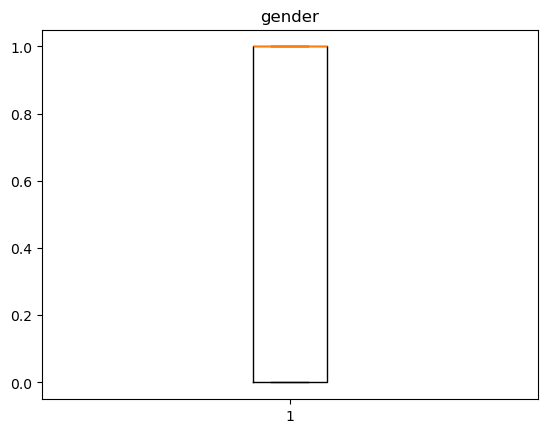

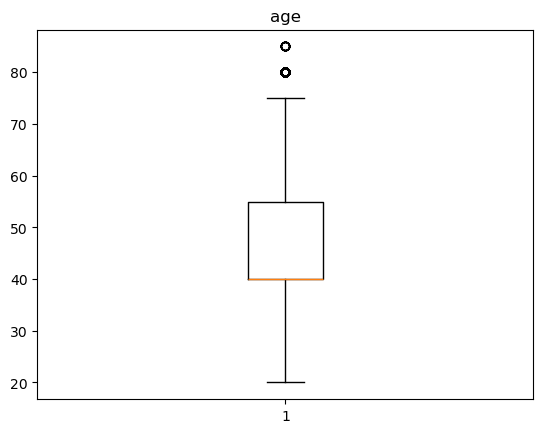

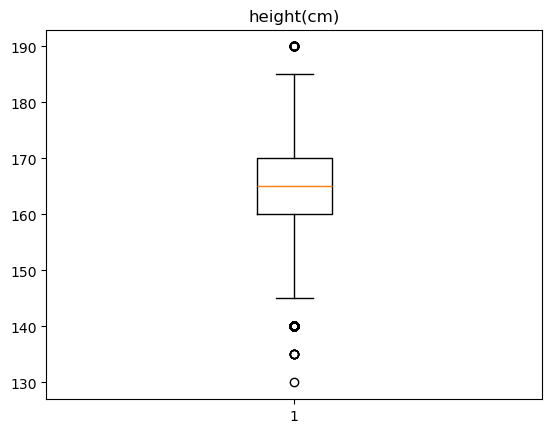

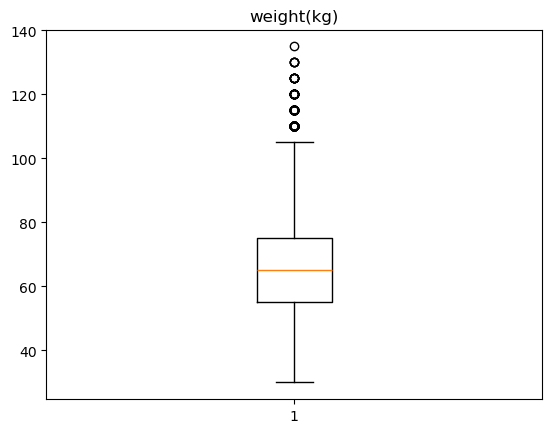

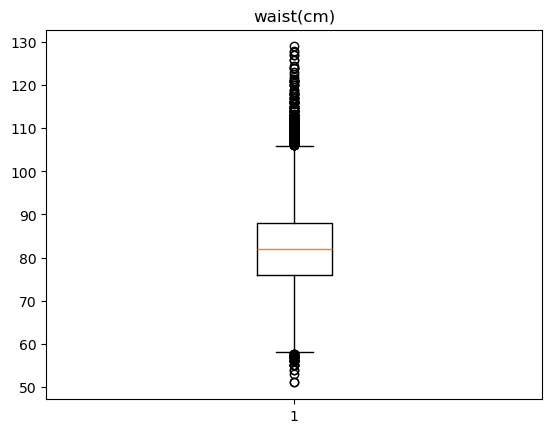

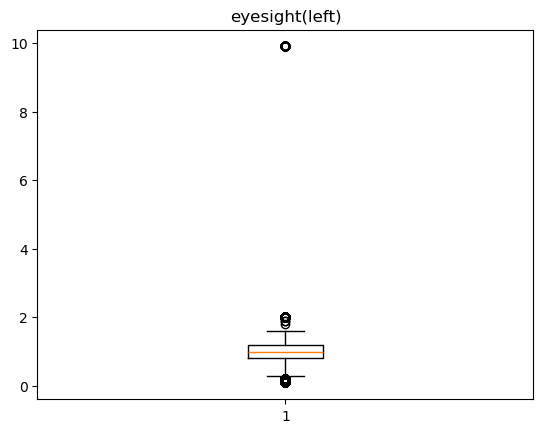

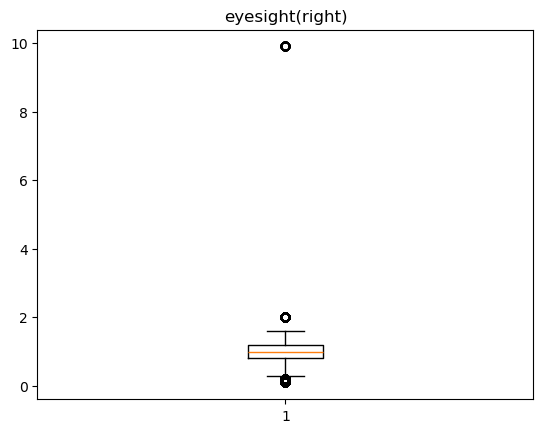

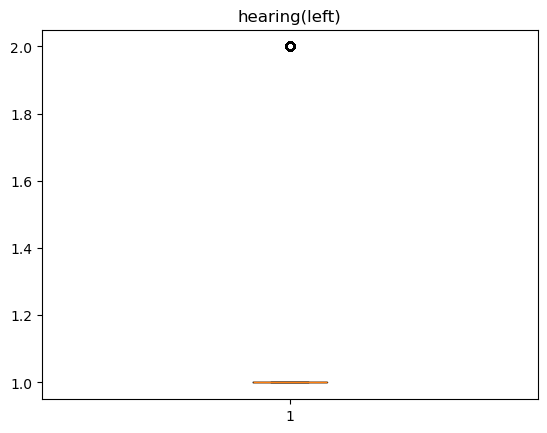

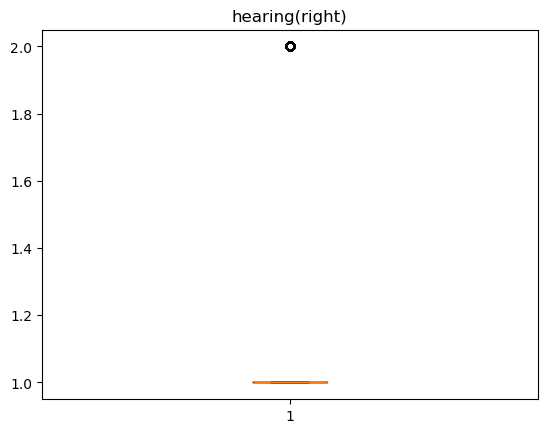

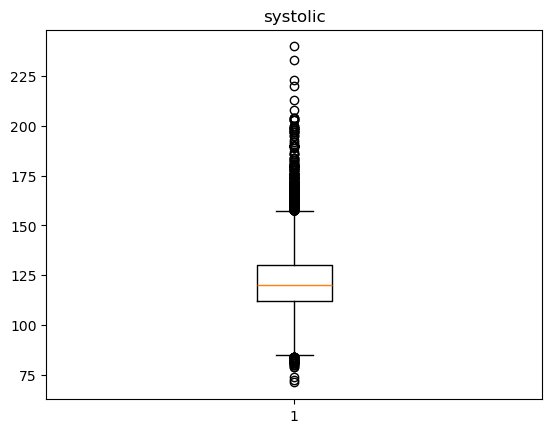

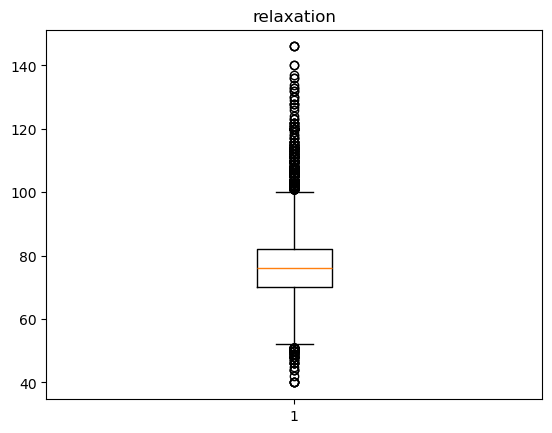

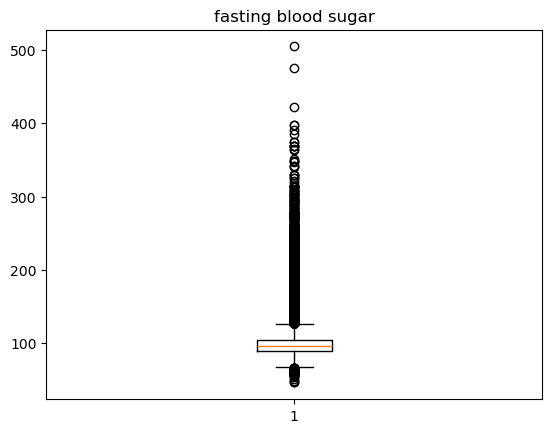

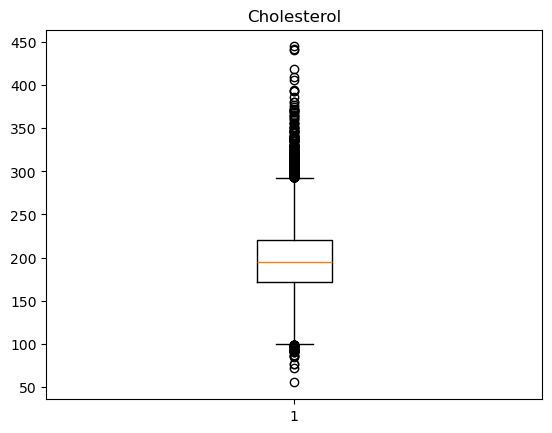

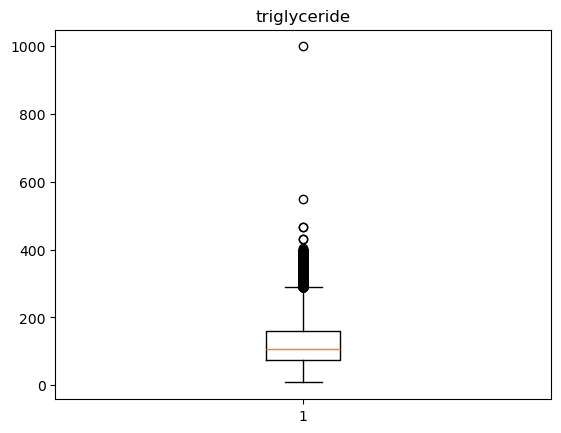

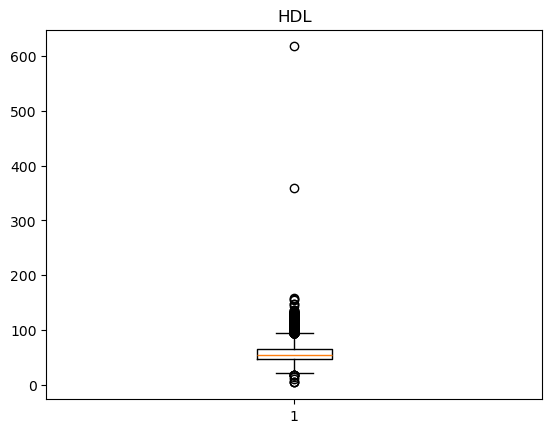

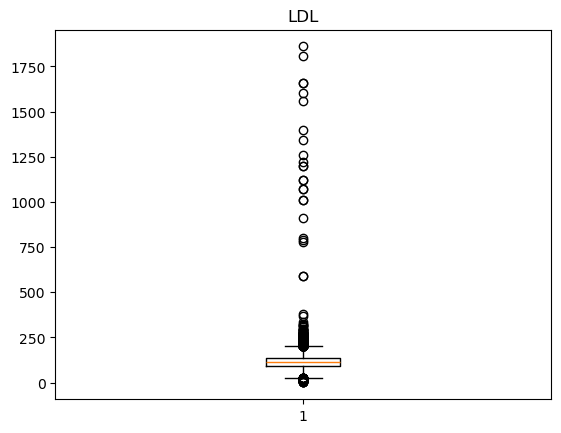

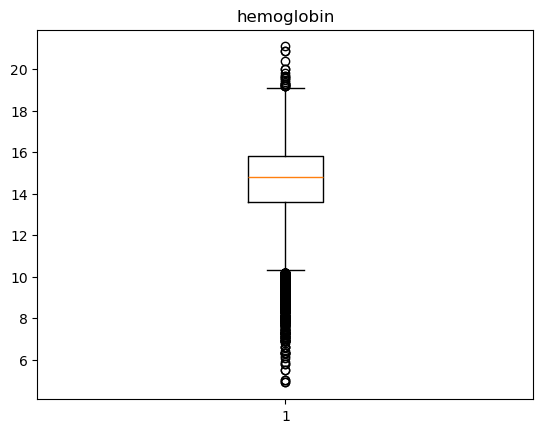

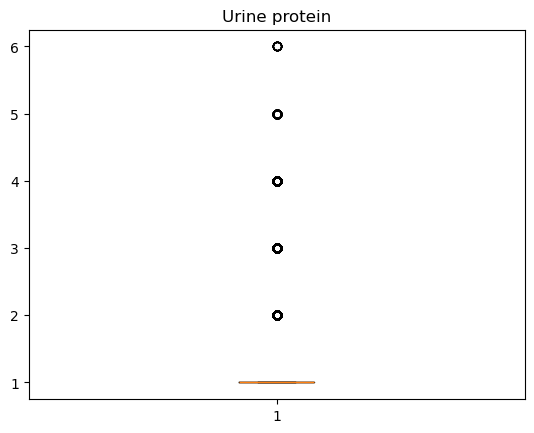

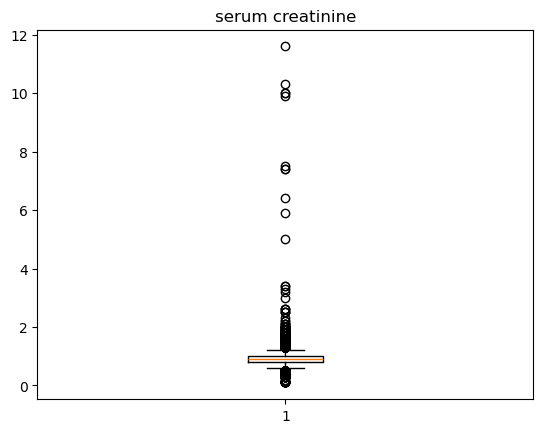

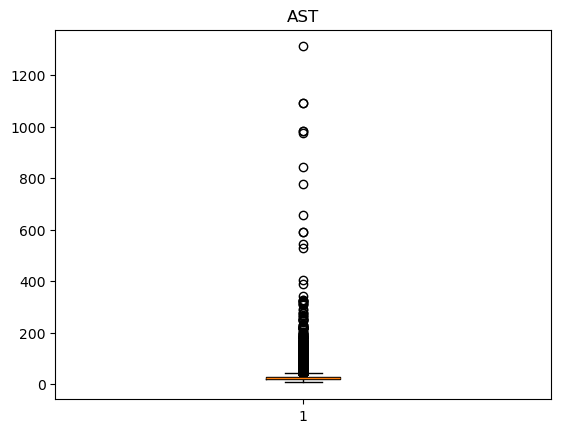

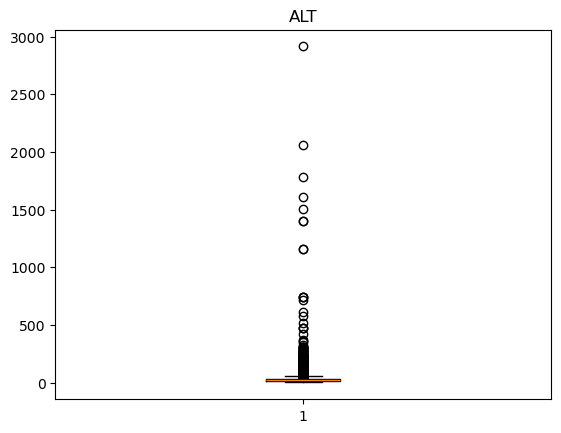

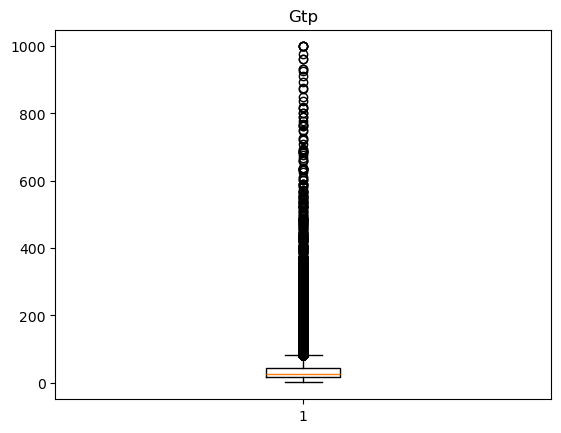

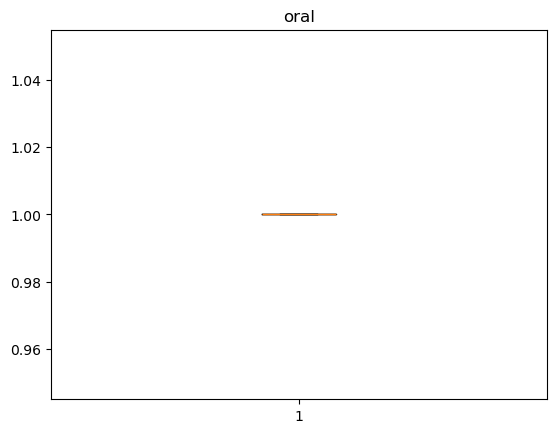

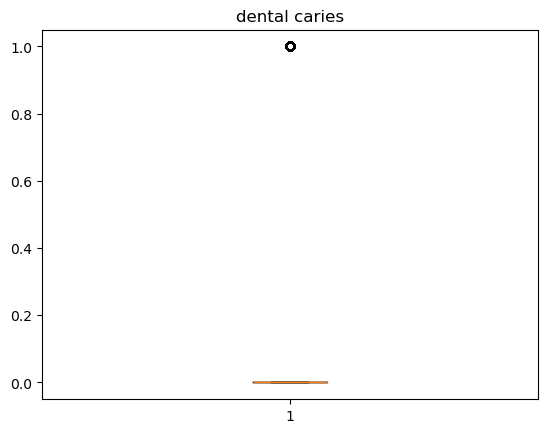

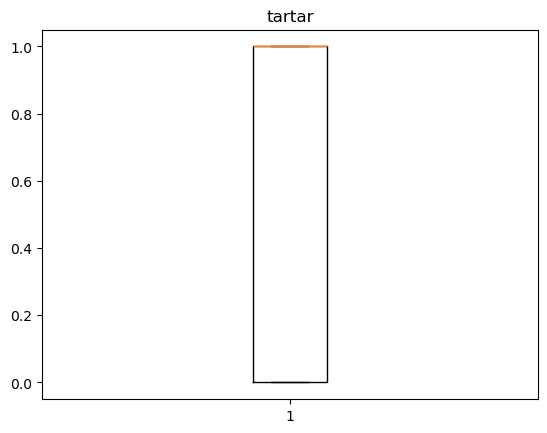

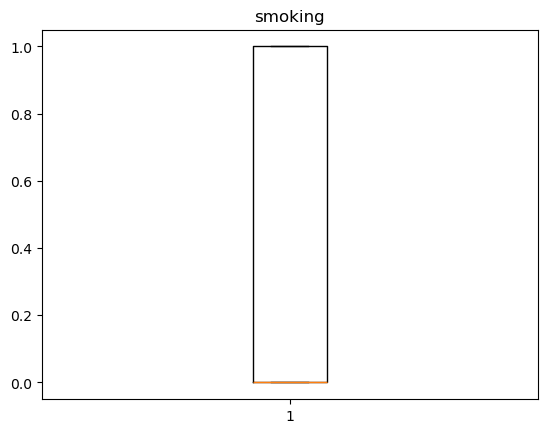

In [69]:
for i in df.select_dtypes([float,int]).columns:
    plt.boxplot(df[i])
    plt.title(i)
    plt.show()

In [70]:
for i in df.select_dtypes(include=['number']).columns:
    q1 = df[i].quantile(0.25)
    q3 = df[i].quantile(0.75)
    iqr = q3 - q1
    lf = q1 - (1.5 * iqr)
    uf = q3 + (1.5 * iqr)

    # Cap values outside the bounds
    df[i] = np.where(df[i] < lf, lf, df[i])
    df[i] = np.where(df[i] > uf, uf, df[i])


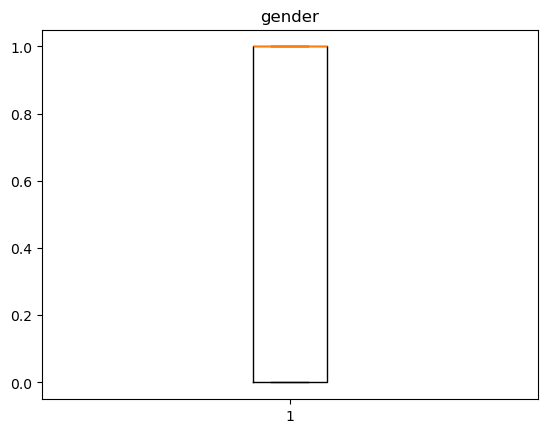

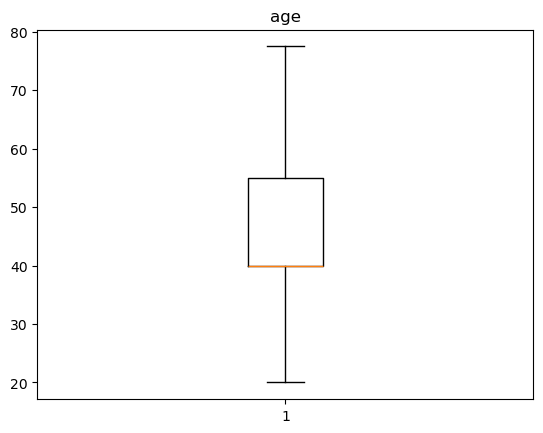

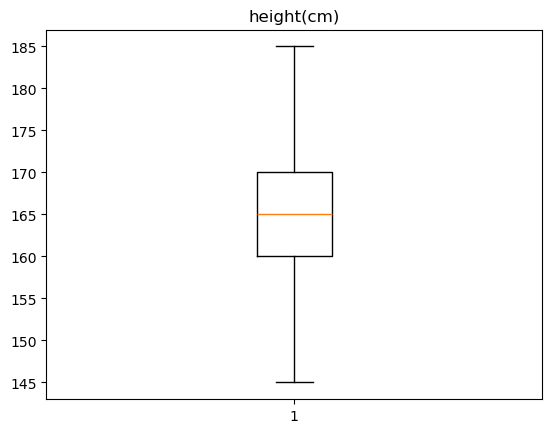

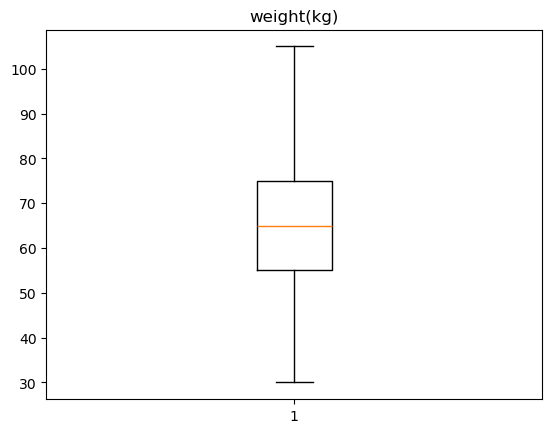

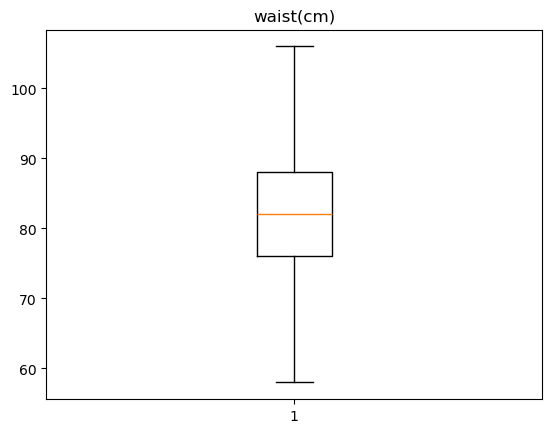

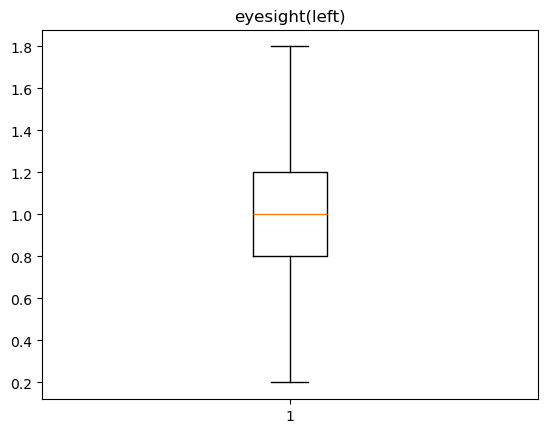

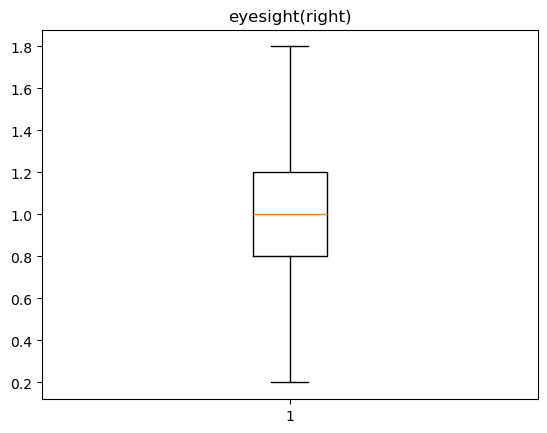

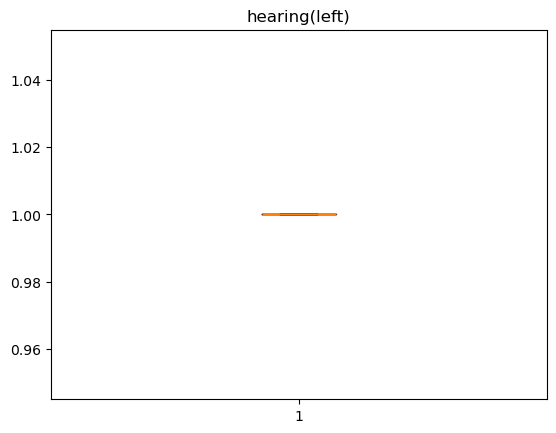

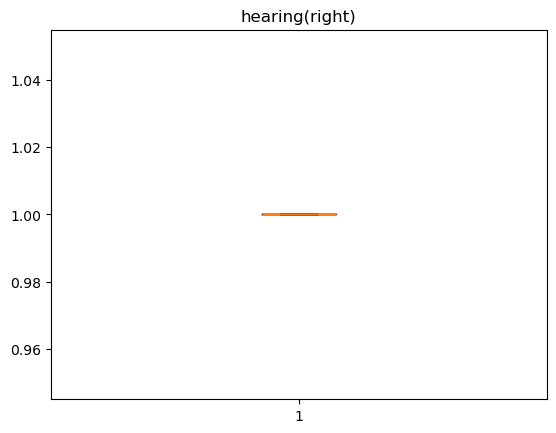

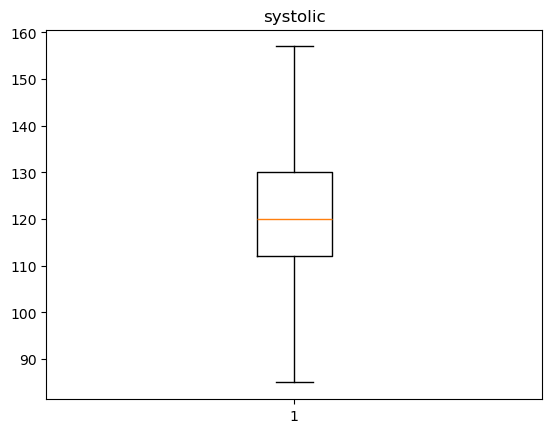

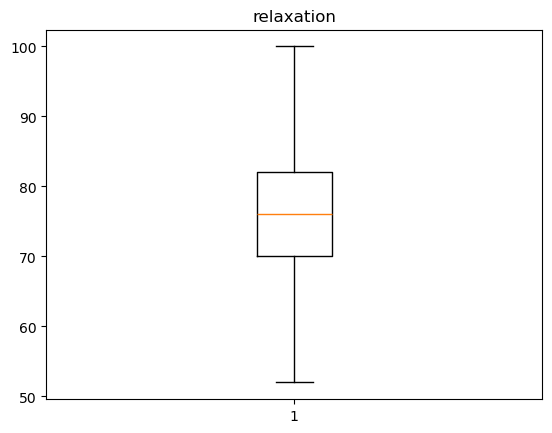

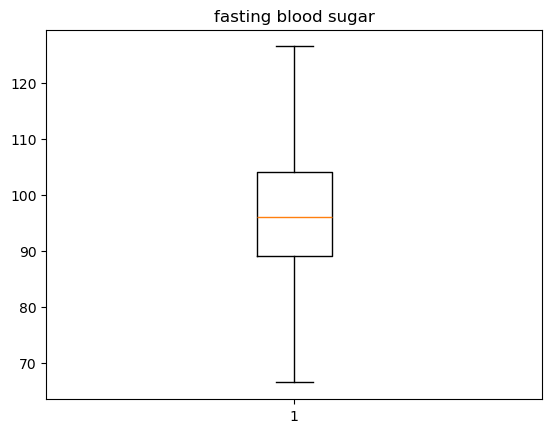

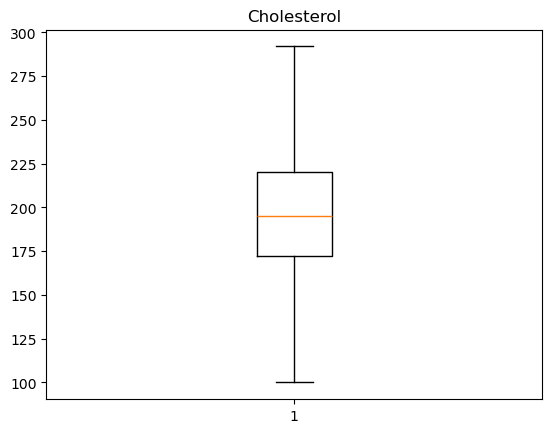

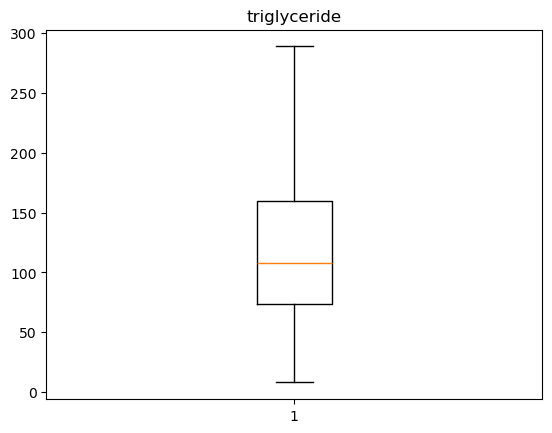

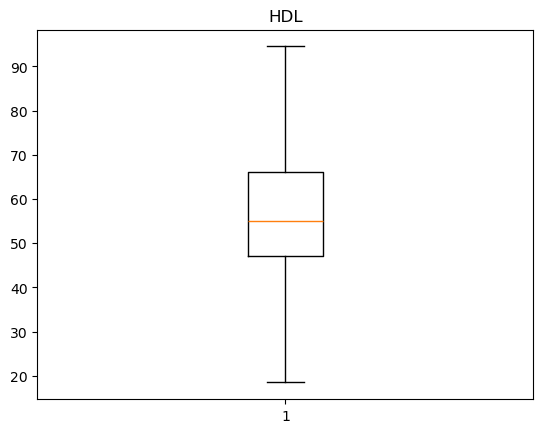

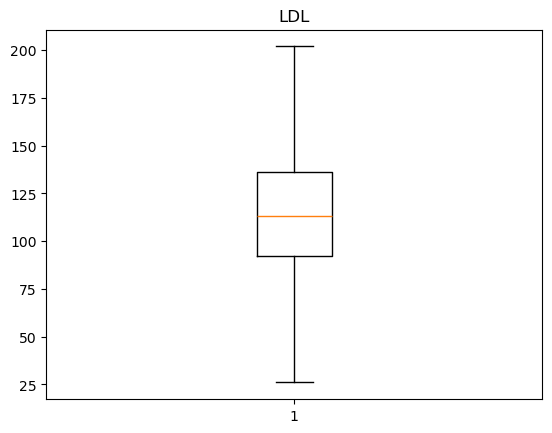

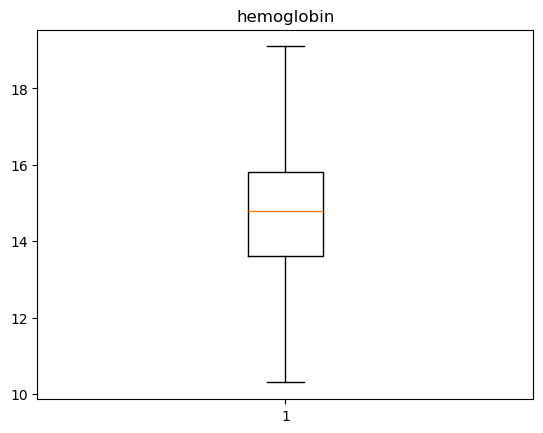

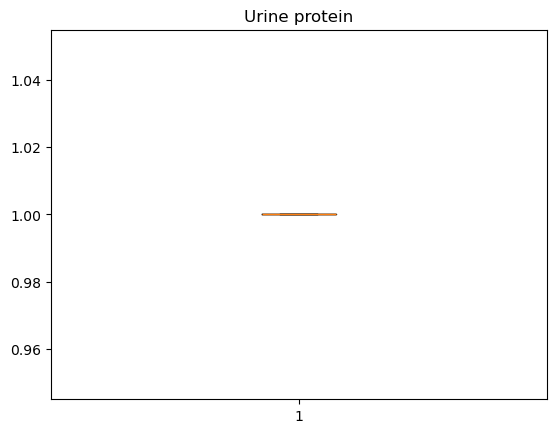

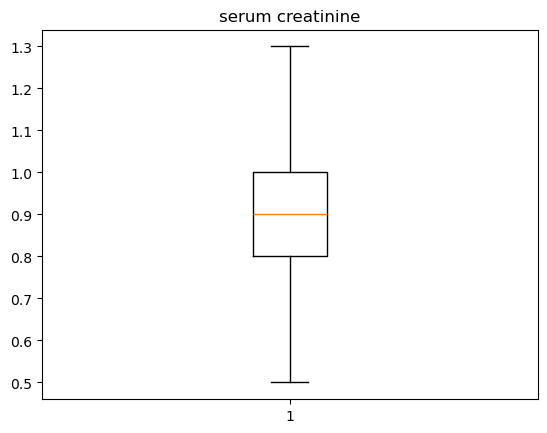

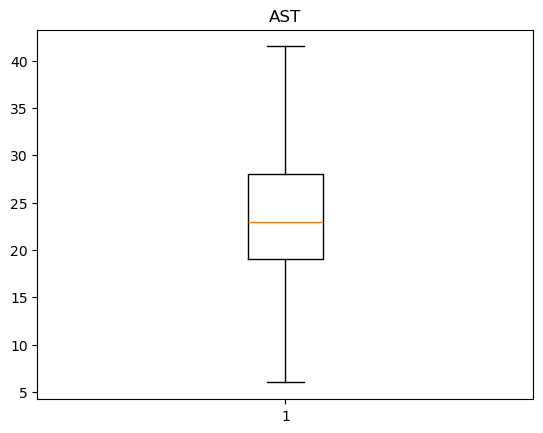

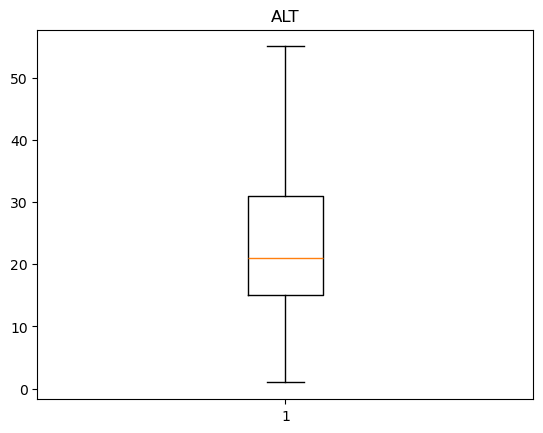

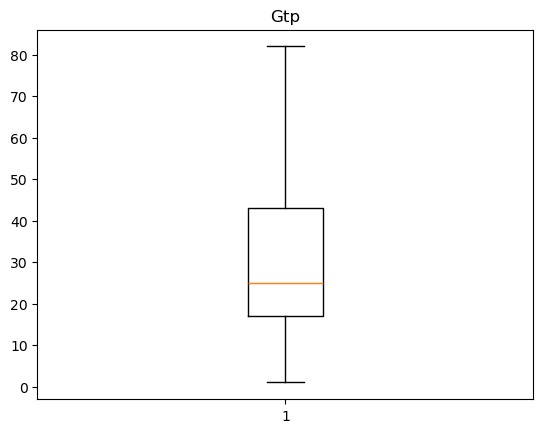

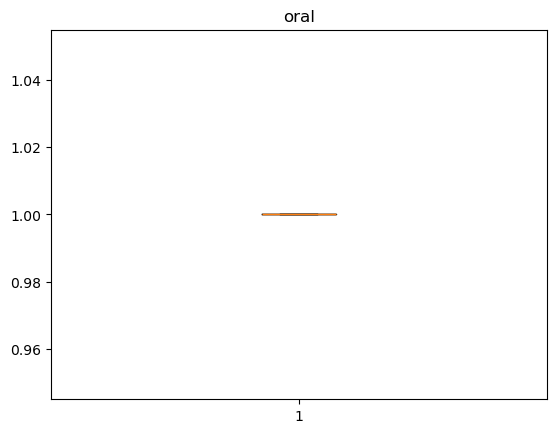

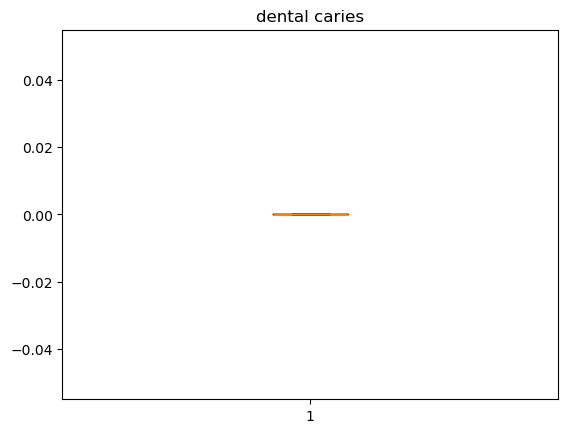

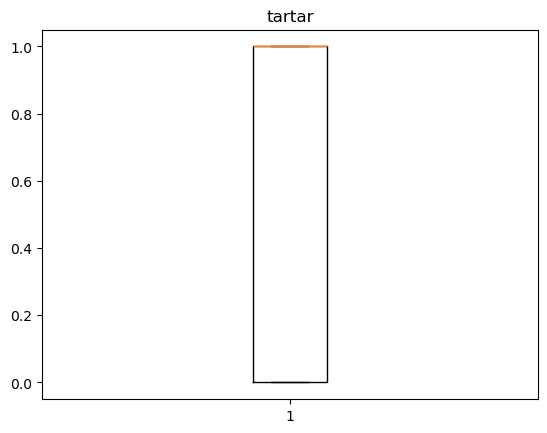

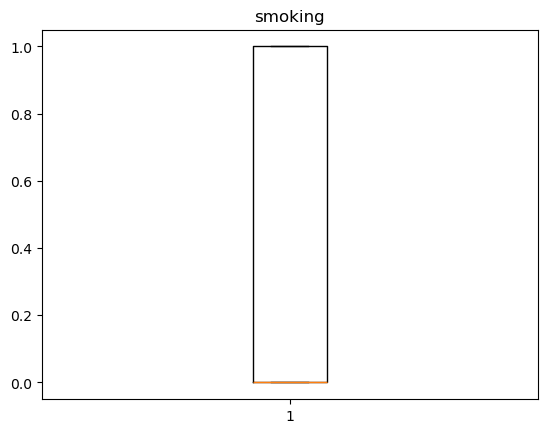

In [71]:
for i in df.select_dtypes([float,int]).columns:
    plt.boxplot(df[i])
    plt.title(i)
    plt.show()

In [72]:
x=df.drop(columns="smoking")
y=df["smoking"]

In [73]:
x_train,x_test, y_train, y_test=train_test_split(x,y,test_size=0.2,random_state=42)


In [74]:
from sklearn.linear_model import LogisticRegression
log=LogisticRegression()

In [75]:
log.fit(x_train,y_train)

LogisticRegression()

In [76]:
from sklearn.tree import DecisionTreeClassifier

In [77]:
dt=DecisionTreeClassifier()
dt.fit(x_train,y_train)
print("train",dt.score(x_train,y_train))
print("test",dt.score(x_test,y_test))

train 1.0
test 0.782027111949008


In [78]:
dt=DecisionTreeClassifier(criterion='gini',max_depth=10,min_samples_split=3,min_samples_leaf=2,random_state=55)

In [79]:
dt.fit(x_train,y_train)
print("Train",dt.score(x_train,y_train))
print("Test",dt.score(x_test,y_test))

Train 0.7885664265032658
Test 0.7367806804919652


In [80]:
dt=DecisionTreeClassifier(max_depth=10, random_state=55)
dt.fit(x_train,y_train)
print("train",dt.score(x_train,y_train))
print("test",dt.score(x_test,y_test))

train 0.7892846721881803
test 0.7375886524822695


In [81]:
dt1=DecisionTreeClassifier(criterion="gini",max_depth=10, min_samples_split=100, random_state=55)

In [82]:
dt1.fit(x_train,y_train)
print("Train",dt1.score(x_train,y_train))
print("Test",dt1.score(x_test,y_test))

Train 0.7797454716854084
Test 0.7371397791543226


In [83]:
cr=["gini","entropy"]
md=[2,4,6,8,10,12]
mss=[10,20,30,40,50,60,70,80,90,100]
for c in cr:
    for m in md:
        for s in mss:
            dt=DecisionTreeClassifier(criterion=c,
                                     max_depth=m,
                                     min_samples_split=s,
                                     random_state=55)
            dt.fit(x_train,y_train)
            print("criterion->{} max_depth-> {} min_sample-> {}".format(c,m,s))
            print("train",dt.score(x_train,y_train))
            print("test",dt.score(x_test,y_test))
            print("*************************************")
            

criterion->gini max_depth-> 2 min_sample-> 10
train 0.7311292168877517
test 0.7215189873417721
*************************************
criterion->gini max_depth-> 2 min_sample-> 20
train 0.7311292168877517
test 0.7215189873417721
*************************************
criterion->gini max_depth-> 2 min_sample-> 30
train 0.7311292168877517
test 0.7215189873417721
*************************************
criterion->gini max_depth-> 2 min_sample-> 40
train 0.7311292168877517
test 0.7215189873417721
*************************************
criterion->gini max_depth-> 2 min_sample-> 50
train 0.7311292168877517
test 0.7215189873417721
*************************************
criterion->gini max_depth-> 2 min_sample-> 60
train 0.7311292168877517
test 0.7215189873417721
*************************************
criterion->gini max_depth-> 2 min_sample-> 70
train 0.7311292168877517
test 0.7215189873417721
*************************************
criterion->gini max_depth-> 2 min_sample-> 80
train 0.731129216887751

In [84]:
cr=["gini","entropy"]
md=[2,4,6,8,10,12]
mss=[10,20,30,40,50,60,70,80,90,100]
train=[]
test=[]
for c in cr:
    for m in md:
        for s in mss:
            dt=DecisionTreeClassifier(criterion=c,
                                     max_depth=m,
                                     min_samples_split=s,
                                     random_state=55)
            dt.fit(x_train,y_train)
            train.append(round(dt.score(x_train,y_train),3))
            test.append(round(dt.score(x_test,y_test),3))
            

In [85]:
print(train)
print("*********")
print(test)

[0.731, 0.731, 0.731, 0.731, 0.731, 0.731, 0.731, 0.731, 0.731, 0.731, 0.741, 0.741, 0.741, 0.741, 0.741, 0.741, 0.741, 0.741, 0.741, 0.741, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.75, 0.763, 0.762, 0.762, 0.762, 0.762, 0.762, 0.762, 0.761, 0.761, 0.761, 0.788, 0.786, 0.785, 0.783, 0.782, 0.782, 0.782, 0.781, 0.78, 0.78, 0.819, 0.813, 0.808, 0.803, 0.8, 0.798, 0.796, 0.793, 0.792, 0.79, 0.731, 0.731, 0.731, 0.731, 0.731, 0.731, 0.731, 0.731, 0.731, 0.731, 0.741, 0.741, 0.741, 0.741, 0.741, 0.741, 0.741, 0.741, 0.741, 0.741, 0.748, 0.747, 0.747, 0.747, 0.747, 0.747, 0.747, 0.747, 0.747, 0.747, 0.762, 0.762, 0.762, 0.761, 0.761, 0.761, 0.761, 0.761, 0.761, 0.761, 0.785, 0.783, 0.782, 0.78, 0.78, 0.779, 0.779, 0.779, 0.778, 0.778, 0.812, 0.806, 0.802, 0.799, 0.796, 0.795, 0.793, 0.792, 0.791, 0.789]
*********
[0.722, 0.722, 0.722, 0.722, 0.722, 0.722, 0.722, 0.722, 0.722, 0.722, 0.73, 0.73, 0.73, 0.73, 0.73, 0.73, 0.73, 0.73, 0.73, 0.73, 0.736, 0.736, 0.736, 0.736, 0.736, 

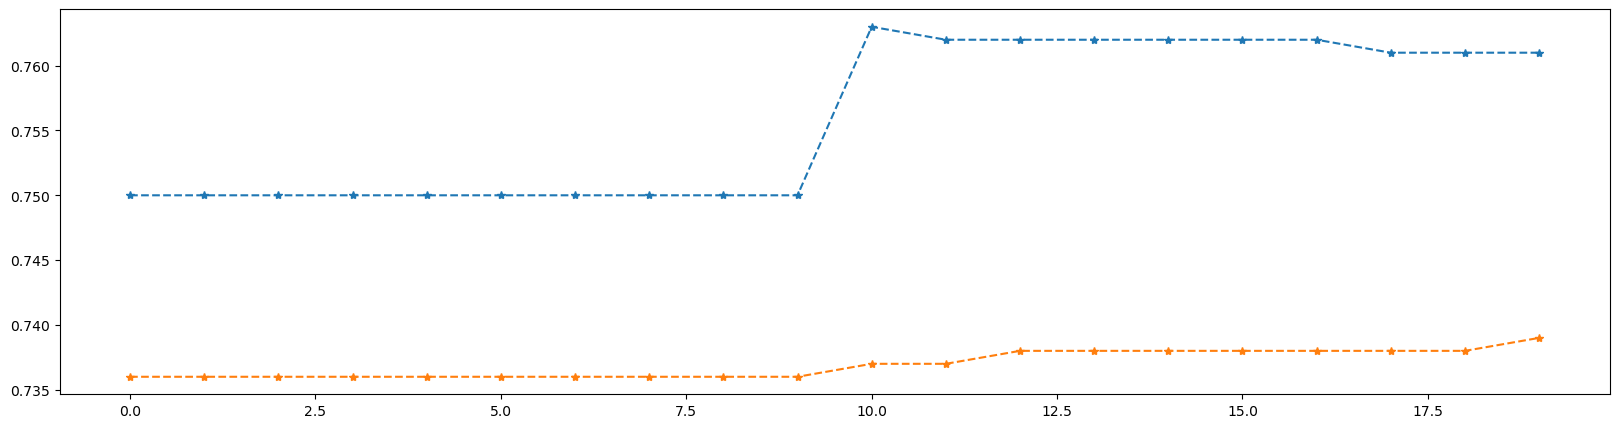

In [98]:
plt.figure(figsize=(20,5))
plt.plot(train[20:],"*--")
plt.plot(test[20:40],"*--")

In [99]:
from sklearn.model_selection import GridSearchCV


In [100]:
cs=["gini","entropy"]
md=[2,4,6,8,10,12]
mss=[10,20,30,40,50,60,70,80,90,100]
for c in cr:
    for m in md:
        for s in mss:
            dt=DecisionTreeClassifier(criterion=c,
                                     max_depth=m,
                                     min_samples_split=s,
                                     random_state=55)


In [89]:
para={"criterion":["gini","entropy"],
     "max_depth":[2,4,6,8,10,12],"min_samples_split":[10,20,30,40,50,60,70,80,90,100]}
tr=DecisionTreeClassifier(random_state=55)
gs=GridSearchCV(tr,param_grid=para)
gs.fit(x_train,y_train)

GridSearchCV(estimator=DecisionTreeClassifier(random_state=55),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [2, 4, 6, 8, 10, 12],
                         'min_samples_split': [10, 20, 30, 40, 50, 60, 70, 80,
                                               90, 100]})

In [90]:
dt=DecisionTreeClassifier(criterion=c,
                                     max_depth=m,
                                     min_samples_split=s,
                                     random_state=55)

In [91]:
dt.fit(x_train,y_train)
print("train",dt.score(x_train,y_train))
print("test",dt.score(x_test,y_test))

train 0.7886786523915337
test 0.7369602298231439


In [92]:
from sklearn.metrics import classification_report


In [93]:
print(classification_report(y_train,dt.predict(x_train)))
print("************")
print(classification_report(y_test,dt.predict(x_test)))

              precision    recall  f1-score   support

         0.0       0.84      0.83      0.83     28210
         1.0       0.71      0.72      0.71     16343

    accuracy                           0.79     44553
   macro avg       0.77      0.77      0.77     44553
weighted avg       0.79      0.79      0.79     44553

************
              precision    recall  f1-score   support

         0.0       0.79      0.79      0.79      7027
         1.0       0.64      0.65      0.64      4112

    accuracy                           0.74     11139
   macro avg       0.72      0.72      0.72     11139
weighted avg       0.74      0.74      0.74     11139



In [94]:
from sklearn import tree


In [95]:
rules=tree.export_text(dt,feature_names=x_train.columns.to_list())

In [96]:
from sklearn.tree import plot_tree

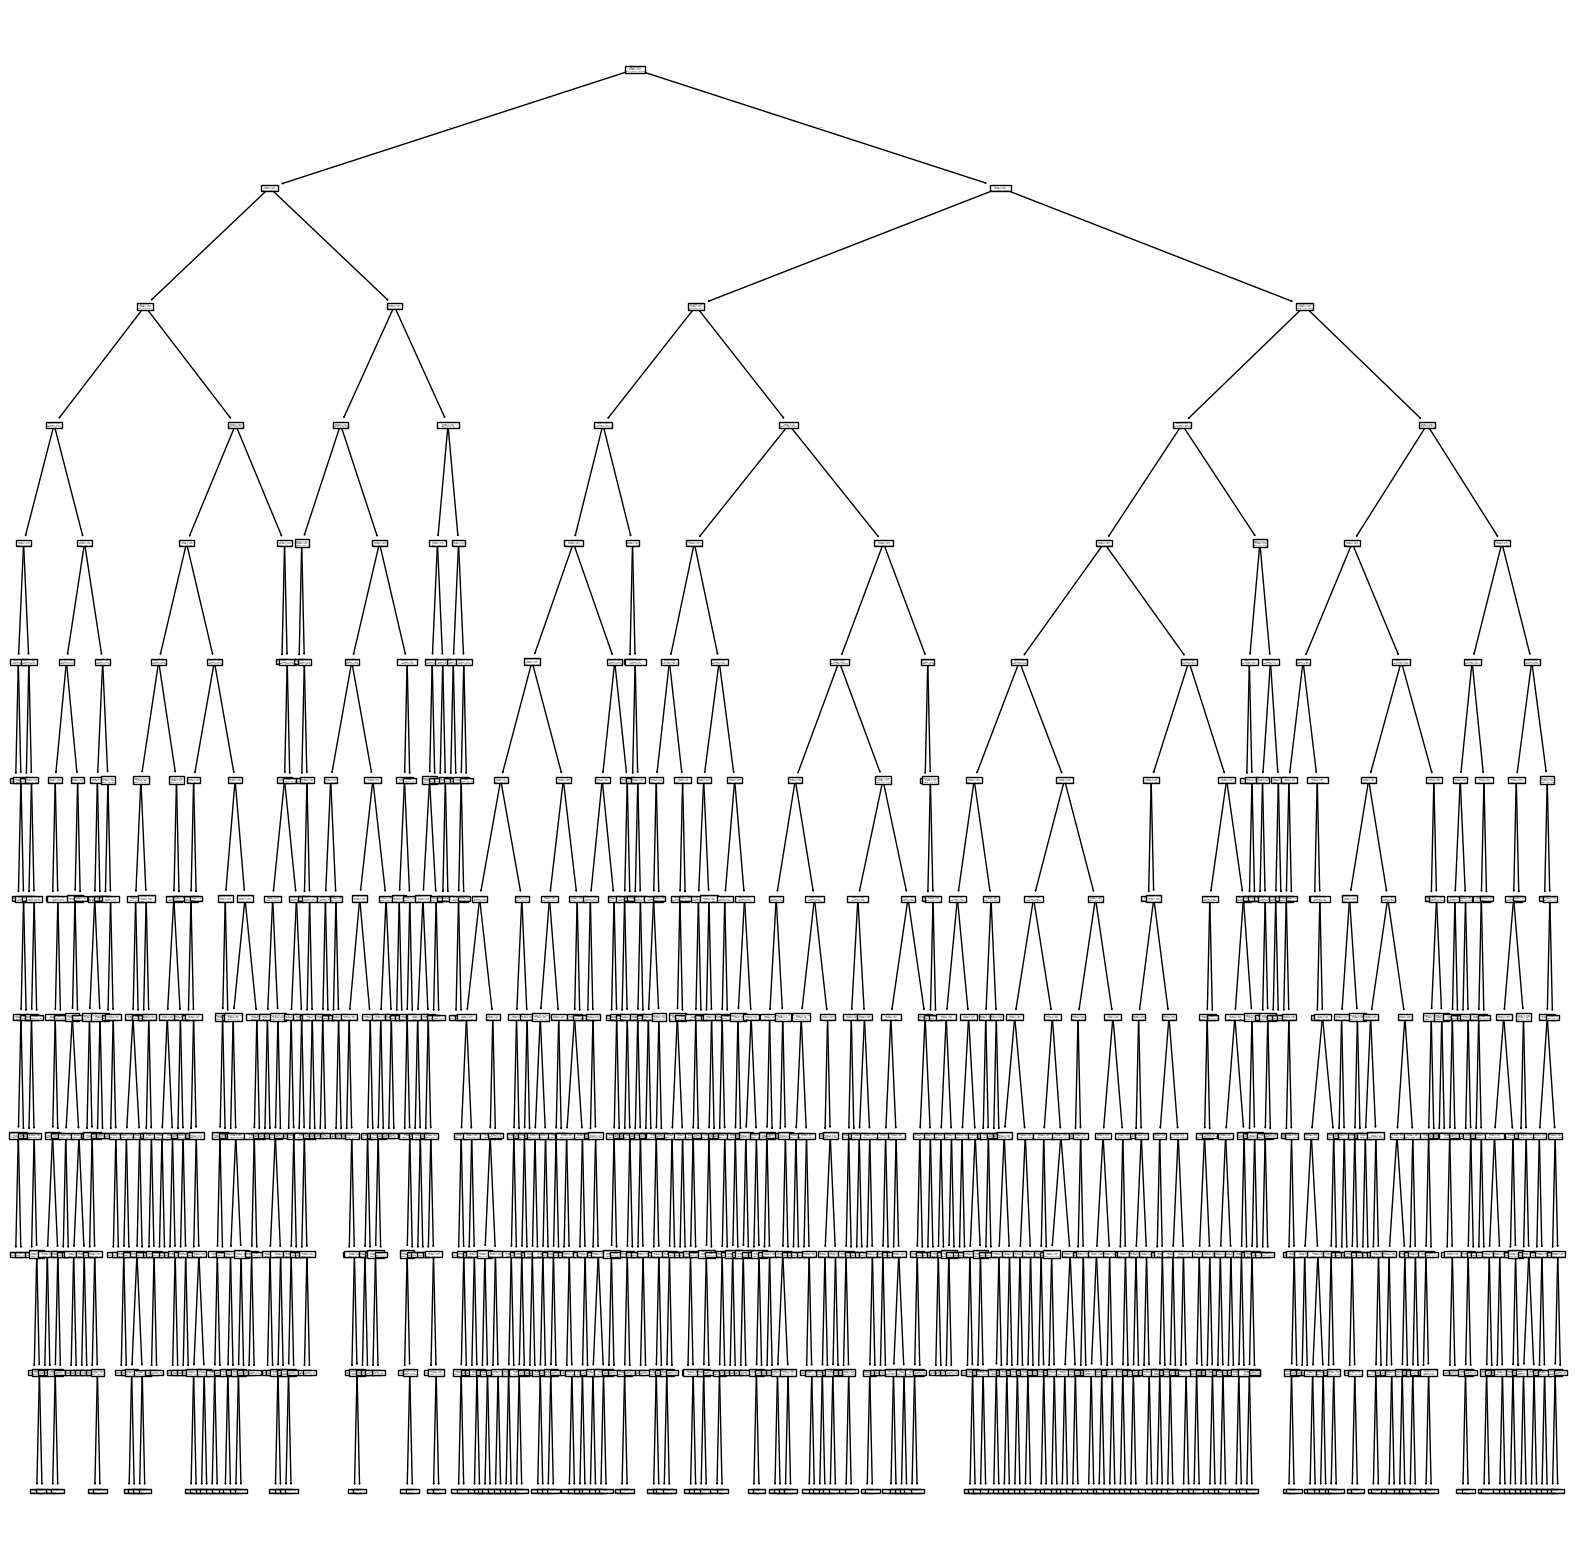

In [97]:
plt.figure(figsize=(20,20))
plot_tree(dt,feature_names=x_train.columns)
plt.show()